In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

In [2]:
try:
    df = pd.read_csv("data/processed/krishijal_master_dataset.csv")
except:
    try:
        df = pd.read_csv("../data/processed/krishijal_master_dataset.csv")
    except:
        df = pd.read_csv("/kaggle/input/krishijal-dataset/krishijal_master_dataset.csv")

In [3]:
df.head()

,record_id,granularity,state,district,zone,latitude,longitude,date,year,month,...,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,nitrogen_status,soil_ph_character,soil_health_index
0,KMD_M_0001,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,1,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
1,KMD_M_0002,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,2,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
2,KMD_M_0003,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,3,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
3,KMD_M_0004,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,4,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
4,KMD_M_0005,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,5,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8


In [4]:
df.shape

(6654, 72)

In [5]:
df.columns

Index(['record_id', 'granularity', 'state', 'district', 'zone', 'latitude',
       'longitude', 'date', 'year', 'month', 'month_name', 'day',
       'day_of_year', 'season', 'crop_type', 'crop_code', 'growth_stage',
       'stage_code', 'crop_coefficient_kc', 'soil_type', 'soil_ph',
       'soil_organic_carbon', 'field_capacity', 'wilting_point', 'temperature',
       'temp_max', 'temp_min', 'rainfall', 'humidity', 'surface_soil_moisture',
       'root_zone_soil_moisture', 'solar_radiation', 'et0', 'etc',
       'effective_soil_wetness', 'stress_coefficient_ks', 'eta', 'cwsi',
       'water_deficit', 'ndvi', 'irrigation_priority_index', 'stress_level',
       'stress_level_code', 'irrigation_priority', 'irrigation_priority_code',
       'cluster_id', 'pca_x', 'pca_y', 'state_lgd_code', 'district_lgd_code',
       'shc_macro_nitrogen_low_share_2024_25',
       'shc_macro_nitrogen_medium_share_2024_25',
       'shc_macro_nitrogen_high_share_2024_25',
       'shc_macro_phosphorus_low_shar

In [6]:
df.dtypes

record_id                                   object
granularity                                 object
state                                       object
district                                    object
zone                                        object
                                            ...   
shc_micro_iron_deficient_share_2024_25     float64
shc_micro_boron_deficient_share_2024_25    float64
nitrogen_status                             object
soil_ph_character                           object
soil_health_index                          float64
Length: 72, dtype: object

In [7]:
df.isnull().sum()

record_id                                  0
granularity                                0
state                                      0
district                                   0
zone                                       0
                                          ..
shc_micro_iron_deficient_share_2024_25     0
shc_micro_boron_deficient_share_2024_25    0
nitrogen_status                            0
soil_ph_character                          0
soil_health_index                          0
Length: 72, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
key_cols = [
    "temperature", "rainfall", "humidity", "effective_soil_wetness",
    "solar_radiation", "ndvi", "et0", "etc", "cwsi", "water_deficit",
    "irrigation_priority_index"
]
df[key_cols].describe()

,temperature,rainfall,humidity,effective_soil_wetness,solar_radiation,ndvi,et0,etc,cwsi,water_deficit,irrigation_priority_index
count,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000
mean,25.745818,4.557325,70.246515,0.630155,17.022613,0.672605,4.086335,4.024665,0.087087,0.259997,21.699970
std,5.535395,9.270983,16.791530,0.170067,4.512583,0.176317,1.145563,1.292759,0.140770,0.613972,13.942208
min,-16.010000,0.000000,16.610000,0.130000,1.720000,0.186000,0.100000,0.090000,0.000000,0.000000,0.800000
25%,23.582500,0.050000,60.872500,0.495000,14.290000,0.580000,3.340000,3.100000,0.000000,0.000000,10.000000
50%,26.570000,1.030000,75.280000,0.642000,17.030000,0.724000,4.130000,3.970000,0.000000,0.000000,19.000000
75%,28.840000,5.640000,83.217500,0.765000,20.020000,0.783000,4.790000,4.900000,0.156000,0.000000,28.875000
max,40.990000,262.610000,96.070000,0.990000,28.430000,0.880000,7.540000,8.180000,0.764000,4.950000,73.700000


In [10]:
df["stress_level"].value_counts()

stress_level
Low         4984
Moderate     910
High         566
Severe       194
Name: count, dtype: int64

In [11]:
df["irrigation_priority"].value_counts()

irrigation_priority
Low         5241
Medium      1091
High         304
Critical      18
Name: count, dtype: int64

In [12]:
df = df.drop_duplicates()

In [13]:
numeric_features = [
    "temperature", "temp_max", "temp_min", "rainfall", "humidity",
    "effective_soil_wetness", "solar_radiation", "soil_ph", "soil_organic_carbon",
    "ndvi", "et0", "etc", "cwsi", "water_deficit", "irrigation_priority_index"
]
for col in numeric_features:
    df[col] = df[col].fillna(df[col].median())

In [14]:
selected_features = [
    "cwsi", "effective_soil_wetness", "water_deficit", "ndvi",
    "et0", "etc", "temperature", "rainfall", "humidity"
]
X = df[selected_features].copy()

In [15]:
stress_mapping = {"Low": 0, "Moderate": 1, "High": 2, "Severe": 3}
y_classification = df["stress_level"].map(stress_mapping)
y_regression = df["irrigation_priority_index"]

In [16]:
X["cwsi"] = X["cwsi"].clip(0.0, 1.0)
X["effective_soil_wetness"] = X["effective_soil_wetness"].clip(0.0, 1.0)
X["ndvi"] = X["ndvi"].clip(0.10, 0.90)
X["water_deficit"] = X["water_deficit"].clip(lower=0.0)

In [17]:
clean_df = X.copy()
clean_df["stress_level_code"] = y_classification
clean_df["irrigation_priority_index"] = y_regression

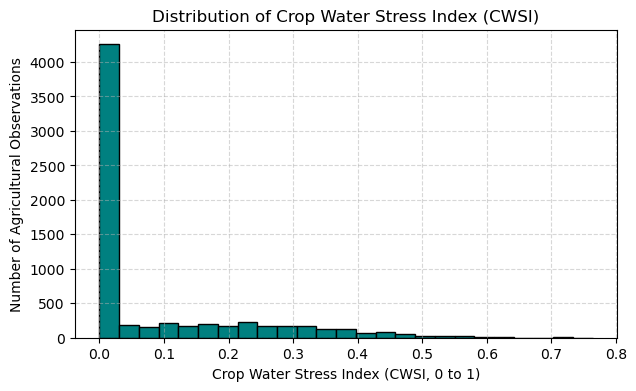

In [18]:
plt.figure(figsize=(7, 4))
plt.hist(clean_df["cwsi"], bins=25, color="teal", edgecolor="black")
plt.title("Distribution of Crop Water Stress Index (CWSI)")
plt.xlabel("Crop Water Stress Index (CWSI, 0 to 1)")
plt.ylabel("Number of Agricultural Observations")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

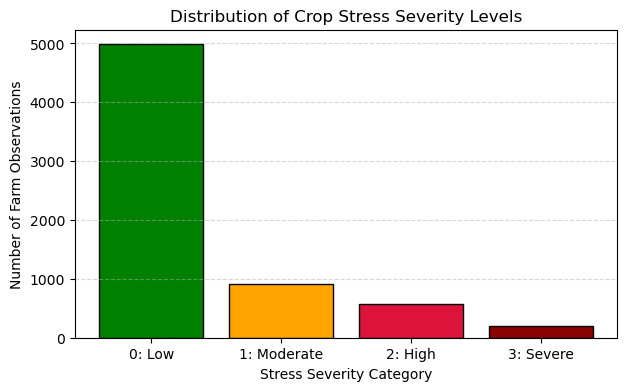

In [19]:
plt.figure(figsize=(7, 4))
stress_counts = clean_df["stress_level_code"].value_counts().sort_index()
stress_labels = ["0: Low", "1: Moderate", "2: High", "3: Severe"]
plt.bar(stress_labels, stress_counts.values, color=["green", "orange", "crimson", "darkred"], edgecolor="black")
plt.title("Distribution of Crop Stress Severity Levels")
plt.xlabel("Stress Severity Category")
plt.ylabel("Number of Farm Observations")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

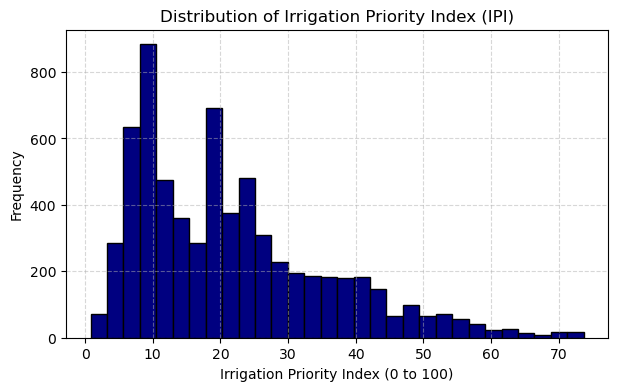

In [20]:
plt.figure(figsize=(7, 4))
plt.hist(clean_df["irrigation_priority_index"], bins=30, color="navy", edgecolor="black")
plt.title("Distribution of Irrigation Priority Index (IPI)")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

/var/folders/37/qg9rk4ks5ll878248d8dyggh0000gn/T/ipykernel_1728/978509750.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="stress_level_code", y="effective_soil_wetness", data=clean_df, palette="YlGnBu")


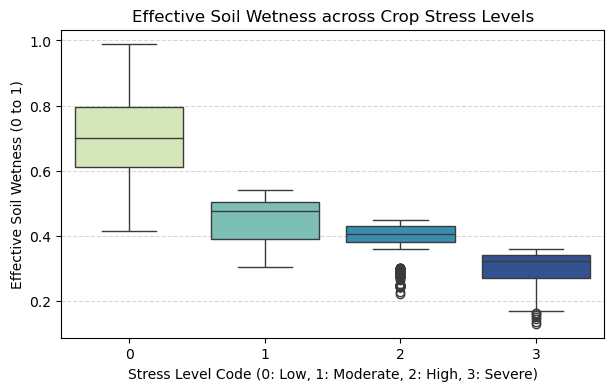

In [21]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="stress_level_code", y="effective_soil_wetness", data=clean_df, palette="YlGnBu")
plt.title("Effective Soil Wetness across Crop Stress Levels")
plt.xlabel("Stress Level Code (0: Low, 1: Moderate, 2: High, 3: Severe)")
plt.ylabel("Effective Soil Wetness (0 to 1)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

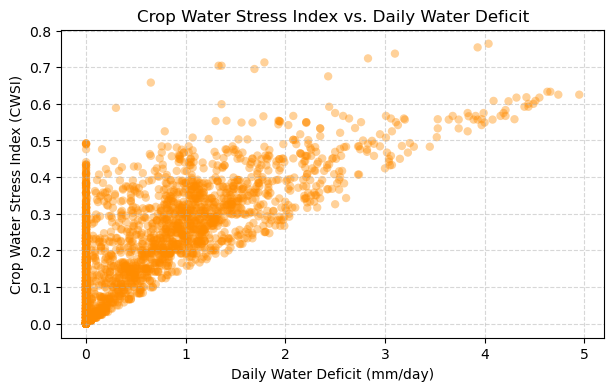

In [22]:
plt.figure(figsize=(7, 4))
plt.scatter(clean_df["water_deficit"], clean_df["cwsi"], alpha=0.4, color="darkorange", edgecolors="none")
plt.title("Crop Water Stress Index vs. Daily Water Deficit")
plt.xlabel("Daily Water Deficit (mm/day)")
plt.ylabel("Crop Water Stress Index (CWSI)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

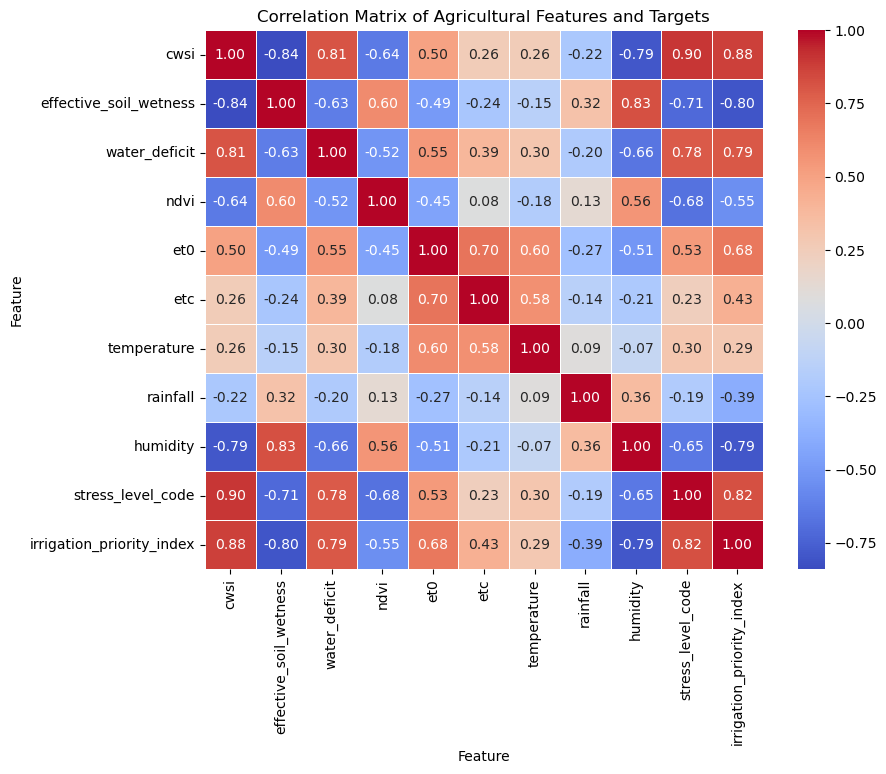

In [23]:
plt.figure(figsize=(9, 7))
sns.heatmap(clean_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix of Agricultural Features and Targets")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

In [24]:
X_train, X_test, y_train_class, y_test_class = train_test_split(
    X, clean_df["stress_level_code"], test_size=0.20, random_state=42, stratify=clean_df["stress_level_code"]
)
_, _, y_train_reg, y_test_reg = train_test_split(
    X, clean_df["irrigation_priority_index"], test_size=0.20, random_state=42
)

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
model_lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train_class)
model_dt_class = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train_class)
model_rf_class = RandomForestClassifier(n_estimators=20, max_depth=5, random_state=42).fit(X_train, y_train_class)

In [27]:
pred_lr = model_lr.predict(X_test_scaled)
pred_dt_class = model_dt_class.predict(X_test)
pred_rf_class = model_rf_class.predict(X_test)

In [28]:
class_results = pd.DataFrame({
    "Algorithm": ["Logistic Regression", "Decision Tree Classifier", "Random Forest Classifier (Initial)"],
    "Accuracy": [
        accuracy_score(y_test_class, pred_lr),
        accuracy_score(y_test_class, pred_dt_class),
        accuracy_score(y_test_class, pred_rf_class)
    ],
    "Precision": [
        precision_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test_class, pred_lr, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ]
})
class_results.round(4)

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9309,0.9299,0.9309,0.9304
1,Decision Tree Classifier,0.9782,0.9798,0.9782,0.9786
2,Random Forest Classifier (Initial),0.9992,0.9992,0.9992,0.9992


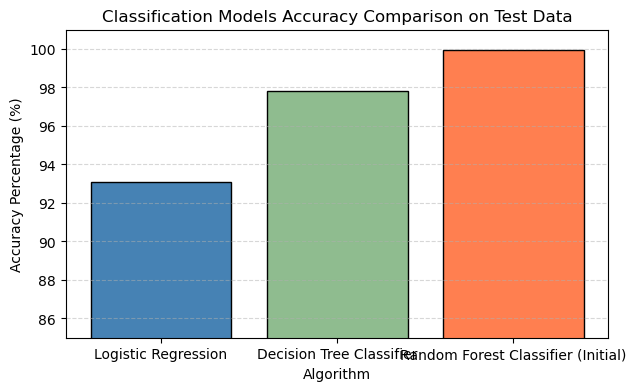

In [29]:
plt.figure(figsize=(7, 4))
plt.bar(class_results["Algorithm"], class_results["Accuracy"] * 100, color=["steelblue", "darkseagreen", "coral"], edgecolor="black")
plt.title("Classification Models Accuracy Comparison on Test Data")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy Percentage (%)")
plt.ylim(85, 101)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

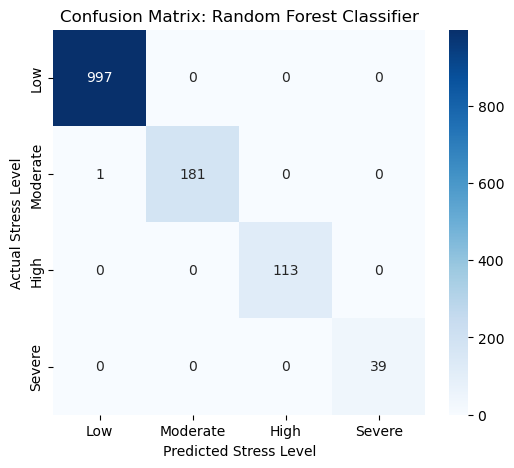

In [30]:
cm = confusion_matrix(y_test_class, pred_rf_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "Moderate", "High", "Severe"], yticklabels=["Low", "Moderate", "High", "Severe"])
plt.title("Confusion Matrix: Random Forest Classifier")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")
plt.show()

In [31]:
model_lin = LinearRegression().fit(X_train_scaled, y_train_reg)
model_dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train_reg)
model_rf_reg = RandomForestRegressor(n_estimators=20, max_depth=5, random_state=42).fit(X_train, y_train_reg)

In [32]:
pred_lin = model_lin.predict(X_test_scaled)
pred_dt_reg = model_dt_reg.predict(X_test)
pred_rf_reg = model_rf_reg.predict(X_test)

In [33]:
reg_results = pd.DataFrame({
    "Algorithm": ["Linear Regression", "Decision Tree Regressor", "Random Forest Regressor (Initial)"],
    "MAE": [
        mean_absolute_error(y_test_reg, pred_lin),
        mean_absolute_error(y_test_reg, pred_dt_reg),
        mean_absolute_error(y_test_reg, pred_rf_reg)
    ],
    "MSE": [
        mean_squared_error(y_test_reg, pred_lin),
        mean_squared_error(y_test_reg, pred_dt_reg),
        mean_squared_error(y_test_reg, pred_rf_reg)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_reg, pred_lin)),
        np.sqrt(mean_squared_error(y_test_reg, pred_dt_reg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_rf_reg))
    ],
    "R2 Score": [
        r2_score(y_test_reg, pred_lin),
        r2_score(y_test_reg, pred_dt_reg),
        r2_score(y_test_reg, pred_rf_reg)
    ]
})
reg_results.round(4)

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,11.1342,191.6396,13.8434,-0.0047
1,Decision Tree Regressor,11.1982,194.8080,13.9574,-0.0213
2,Random Forest Regressor (Initial),11.1320,191.9190,13.8535,-0.0061


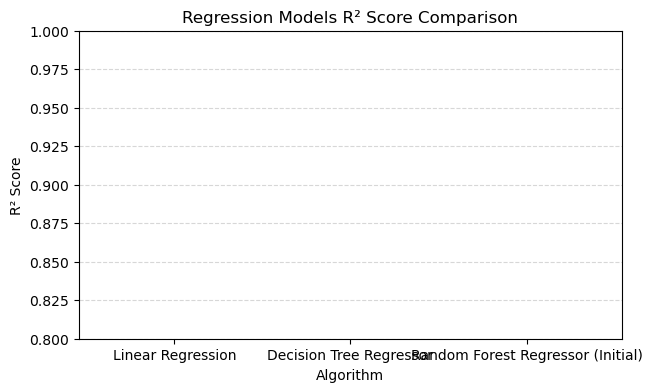

In [34]:
plt.figure(figsize=(7, 4))
plt.bar(reg_results["Algorithm"], reg_results["R2 Score"], color=["lightskyblue", "lightgreen", "salmon"], edgecolor="black")
plt.title("Regression Models R² Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("R² Score")
plt.ylim(0.8, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [35]:
param_grid_rf = {
    "n_estimators": [30, 50, 100],
    "max_depth": [6, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_search_rf.fit(X_train, y_train_class)
grid_search_rf.best_params_

{'max_depth': None,
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 100}

In [36]:
tuned_rf_class = grid_search_rf.best_estimator_
pred_tuned_class = tuned_rf_class.predict(X_test)
tuning_comparison = pd.DataFrame({
    "Model Version": ["Initial Random Forest (n=20, max_depth=5)", "Tuned Random Forest (GridSearchCV)"],
    "Accuracy": [
        accuracy_score(y_test_class, pred_rf_class),
        accuracy_score(y_test_class, pred_tuned_class)
    ],
    "F1-Score": [
        f1_score(y_test_class, pred_rf_class, average="weighted"),
        f1_score(y_test_class, pred_tuned_class, average="weighted")
    ]
})
tuning_comparison.round(4)

,Model Version,Accuracy,F1-Score
0,"Initial Random Forest (n=20, max_depth=5)",0.9992,0.9992
1,Tuned Random Forest (GridSearchCV),1.0000,1.0000


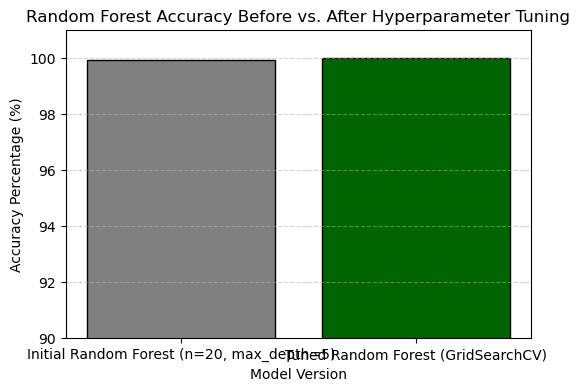

In [37]:
plt.figure(figsize=(6, 4))
plt.bar(tuning_comparison["Model Version"], tuning_comparison["Accuracy"] * 100, color=["gray", "darkgreen"], edgecolor="black")
plt.title("Random Forest Accuracy Before vs. After Hyperparameter Tuning")
plt.xlabel("Model Version")
plt.ylabel("Accuracy Percentage (%)")
plt.ylim(90, 101)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [38]:
param_grid_reg = {
    "n_estimators": [30, 50, 80],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 4]
}
grid_search_reg = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_reg,
    cv=3,
    scoring="r2",
    n_jobs=-1
)
grid_search_reg.fit(X_train, y_train_reg)
tuned_rf_reg = grid_search_reg.best_estimator_
pred_tuned_reg = tuned_rf_reg.predict(X_test)
r2_score(y_test_reg, pred_tuned_reg)

-0.006524070501691792

In [39]:
farmer_scenarios = pd.DataFrame([
    {
        "cwsi": 0.05, "effective_soil_wetness": 0.65, "water_deficit": 0.0,
        "ndvi": 0.72, "et0": 4.2, "etc": 4.5, "temperature": 27.5, "rainfall": 5.0, "humidity": 70.0
    },
    {
        "cwsi": 0.28, "effective_soil_wetness": 0.40, "water_deficit": 1.2,
        "ndvi": 0.58, "et0": 5.1, "etc": 5.5, "temperature": 32.0, "rainfall": 0.0, "humidity": 52.0
    },
    {
        "cwsi": 0.68, "effective_soil_wetness": 0.20, "water_deficit": 3.8,
        "ndvi": 0.38, "et0": 6.5, "etc": 7.0, "temperature": 38.0, "rainfall": 0.0, "humidity": 35.0
    }
])
farmer_scenarios

,cwsi,effective_soil_wetness,water_deficit,ndvi,et0,etc,temperature,rainfall,humidity
0,0.05,0.65,0.0,0.72,4.2,4.5,27.5,5.0,70.0
1,0.28,0.40,1.2,0.58,5.1,5.5,32.0,0.0,52.0
2,0.68,0.20,3.8,0.38,6.5,7.0,38.0,0.0,35.0


In [40]:
pred_scenarios_class = tuned_rf_class.predict(farmer_scenarios)
pred_scenarios_reg = tuned_rf_reg.predict(farmer_scenarios)
stress_label_map = {0: "Low", 1: "Moderate", 2: "High", 3: "Severe"}
for i in range(len(farmer_scenarios)):
    print("Scenario", chr(65 + i), ": Stress =", stress_label_map[pred_scenarios_class[i]], "| Priority =", round(pred_scenarios_reg[i], 1))

Scenario A : Stress = Low | Priority = 22.4
Scenario B : Stress = High | Priority = 22.2
Scenario C : Stress = Severe | Priority = 23.2


In [41]:
if os.path.exists("../models"):
    model_dir = "../models/saved_models"
else:
    model_dir = "models/saved_models"

os.makedirs(model_dir, exist_ok=True)
joblib.dump(tuned_rf_class, model_dir + "/crop_stress_classifier.joblib")
joblib.dump(tuned_rf_reg, model_dir + "/irrigation_priority_regressor.joblib")
joblib.dump(scaler, model_dir + "/feature_scaler.joblib")

metadata = {
    "project": "Crop Stress and Irrigation Priority Decision Support System",
    "feature_names": selected_features,
    "stress_label_map": stress_label_map,
    "best_classifier": "RandomForestClassifier",
    "best_classifier_params": tuned_rf_class.get_params(),
    "best_regressor": "RandomForestRegressor"
}

with open(model_dir + "/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

In [42]:
loaded_clf = joblib.load(model_dir + "/crop_stress_classifier.joblib")
loaded_reg = joblib.load(model_dir + "/irrigation_priority_regressor.joblib")
stress_label_map[loaded_clf.predict(farmer_scenarios.iloc[[1]])[0]]

'High'